# Getting Started... with JAX

Welcome to the JAX side of petitRADTRANS!

This notebook complements ["Getting Started"](./getting_started.ipynb) and ["Retrievals: Using the Model Functions"](./retrieval_model_functions_tutorial.ipynb). Its goal is to introduce the JAX features that matter most when building and fitting atmospheric models with petitRADTRANS version 4.

We will cover:

- NumPy-like array programming with `jax.numpy`.
- just-in-time compilation with `jax.jit`.
- automatic differentiation with `jax.grad` and `jax.jacfwd`.
- batch evaluation with `jax.vmap`.
- moving the same model code between CPU and GPU devices.

The final section reproduces an important retrieval pattern: calculating the derivative of the spectrum with respect to model parameters as a function of wavelength, following the same idea used in internal JAX retrieval test notebooks.

Useful JAX references while reading this notebook are the [JAX quickstart](https://docs.jax.dev/en/latest/quickstart.html), [Thinking in JAX](https://docs.jax.dev/en/latest/notebooks/thinking_in_jax.html), and the [automatic differentiation guide](https://docs.jax.dev/en/latest/automatic-differentiation.html).

## Imports and Floating-Point Precision

We start exactly as in the ["Getting Started"](./getting_started.ipynb) notebook: enable JAX 64-bit mode before importing any petitRADTRANS modules. See the [JAX quickstart](https://docs.jax.dev/en/latest/quickstart.html) and [Default dtypes and the X64 flag](https://docs.jax.dev/en/latest/default_dtypes.html) for background.

<div class="alert alert-warning">

JAX floating point precision must be set before importing any petitRADTRANS modules. Double precision is especially important for scattering in emission and for stable derivative calculations in retrieval workflows.

</div>

In [1]:
from jax import config
config.update("jax_enable_x64", True)

import time

import jax
from jax import grad, jacfwd, jit, vmap
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

import petitRADTRANS as prt
from petitRADTRANS import physical_constants as cst
from petitRADTRANS.radtrans import Radtrans
from petitRADTRANS.retrieval.models import guillot_emission
from petitRADTRANS.retrieval.runtime import ModelContext, PhysicalParams

print(f"petitRADTRANS version: {prt.__version__}")
print(f"JAX version: {jax.__version__}")

petitRADTRANS version: 4.0.0a28
JAX version: 0.8.2


## 1. `jax.numpy` Looks and Feels Like NumPy

The easiest way to get started with JAX is to treat it as a NumPy-like array library. In pRT this shows up immediately when defining pressure grids, temperature profiles, and abundance arrays.

A few practical differences matter:

- JAX arrays are immutable, so updates use `.at[...]` instead of in-place assignment.
- `jax.numpy` operations produce JAX arrays that can be traced by `jit`, `grad`, and `vmap`.
- The same code can run on CPU, GPU, or TPU depending on your JAX installation. See the [`jax.numpy` API](https://docs.jax.dev/en/latest/jax.numpy.html).

In [2]:
numpy_pressures = np.logspace(-6, 2, 5)
jax_pressures = jnp.logspace(-6, 2, 5)

abundance_profile = 1e-3 * jnp.ones(8)
abundance_profile = abundance_profile.at[4:].set(3e-4)

print("NumPy pressures:", numpy_pressures)
print("JAX pressures:", np.asarray(jax_pressures))
print("Same values:", np.allclose(numpy_pressures, np.asarray(jax_pressures)))
print("Immutable update with .at[]:", np.asarray(abundance_profile))

NumPy pressures: [1.e-06 1.e-04 1.e-02 1.e+00 1.e+02]
JAX pressures: [1.e-06 1.e-04 1.e-02 1.e+00 1.e+02]
Same values: True
Immutable update with .at[]: [0.001  0.001  0.001  0.001  0.0003 0.0003 0.0003 0.0003]


## 2. Devices and Execution Backends

JAX automatically targets the best available backend. On a laptop that is often the CPU, while on a workstation or cluster it may be a GPU. The pRT model code itself does not change: device placement is handled by JAX. See the [JAX installation guide](https://docs.jax.dev/en/latest/installation.html) for backend-specific setup details.

In [3]:
print("Default backend:", jax.default_backend())
print("Available devices:")
for device in jax.devices():
    print("  ", device)

device_array = jax.device_put(jax_pressures)
print("Pressure grid lives on:", device_array.devices())

Default backend: cpu
Available devices:
   TFRT_CPU_0
Pressure grid lives on: {CpuDevice(id=0)}


## 3. Building a Differentiable petitRADTRANS Model

For the JAX examples below we will use the runtime-native retrieval API: a `ModelContext` containing the `Radtrans` object and evaluation flags, and a `PhysicalParams` container holding the model parameters.

This is the interface that composes naturally with JAX transformations because `PhysicalParams` is a pytree. That means you can apply `jit`, `grad`, `jacfwd`, and `vmap` to model functions such as `guillot_emission` without writing a separate legacy adapter.

<div class="alert alert-info">

The first time you request one of these opacities, pRT may ask you to download or choose the relevant line list. This is normal and follows the same behavior as in ["Getting Started"](./getting_started.ipynb).

</div>

In [4]:
pressures = jnp.logspace(-6, 2, 80)

atmosphere = Radtrans(
    pressures=pressures,
    line_species=(
        "H2O__POKAZATEL.R200",
        "CO-NatAbund.R200",
        "CH4.R200",
        "CO2.R200",
    ),
    rayleigh_species=("H2", "He"),
    gas_continuum_contributors=("H2--H2", "H2--He"),
    cloud_species=(),
    line_opacity_mode="c-k",
    wavelength_boundaries=(1.0, 3.0),
    scattering_in_emission=False,
)

emission_context = ModelContext(
    name="jax_tutorial_emission",
    mode="evaluate",
    radtrans=atmosphere,
    adaptive_mesh_refinement=False,
    return_contribution=False,
)

base_parameter_mapping = {
    "log_g": 4.0,
    "distance_to_system": 20.0 * cst.pc,
    "planet_radius": 1.0 * cst.r_jup_mean,
    "T_int": 700.0,
    "T_equ": 900.0,
    "gamma": 0.2,
    "log_kappa_IR": -2.0,
    "H2O__POKAZATEL": -3.0,
    "CO-NatAbund": -3.5,
    "CH4": -6.0,
    "CO2": -5.0,
}

physical_params = PhysicalParams.from_mapping(base_parameter_mapping)

Loading Radtrans opacities...
 Loading line opacities of species 'H2O__POKAZATEL.R200' from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/lines/correlated_k/H2O/1H2-16O/1H2-16O__POKAZATEL.R200_0.3-50mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species 'CO-NatAbund.R200' from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/lines/correlated_k/CO/C-O-NatAbund/C-O-NatAbund__HITEMP.R200_0.1-250mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species 'CH4.R200' from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/lines/correlated_k/CH4/12C-1H4/12C-1H4__MM.R200_0.3-50mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species 'CO2.R200' from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/lines/correlated_k/CO2/12C-16O2/12C-16O2__UCL-4000.R200_0.3-50mu.ktable.petitRADTRANS.h5'... Done.
 Successfully loaded all line opacities
 Loading CIA opacities

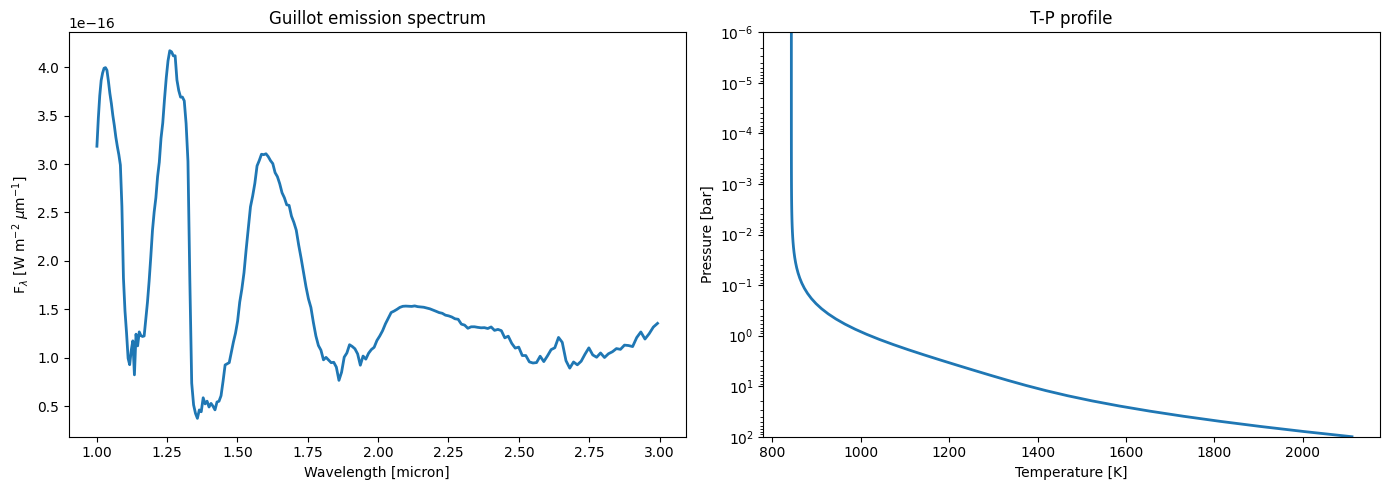

In [5]:
emission_result = guillot_emission(emission_context, physical_params)
pt_result = guillot_emission(emission_context, physical_params, pt_plot_mode=True)

wavelengths = emission_result.wavelengths
flux = emission_result.spectrum

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(np.asarray(wavelengths), np.asarray(flux), linewidth=2)
axes[0].set_xlabel("Wavelength [micron]")
axes[0].set_ylabel(r"F$_{\lambda}$ [W m$^{-2}$ $\mu$m$^{-1}$]")
axes[0].set_title("Guillot emission spectrum")

axes[1].plot(np.asarray(pt_result.temperatures), np.asarray(pt_result.pressures), linewidth=2)
axes[1].set_xlabel("Temperature [K]")
axes[1].set_ylabel("Pressure [bar]")
axes[1].set_yscale("log")
axes[1].set_ylim(1e2, 1e-6)
axes[1].set_title("T-P profile")

fig.tight_layout()

## 4. JIT Compilation with `jax.jit`

`jit` traces a pure Python function once, compiles it for the active backend, and then reuses the compiled executable on later calls with the same input structure. See the [JIT compilation guide](https://docs.jax.dev/en/latest/jit-compilation.html).

This is especially useful in atmospheric retrievals because the same forward model is evaluated many times while only the parameter values change. The first call pays the compilation cost; the following calls reuse the compiled model.

In [6]:
dynamic_parameter_names = ("T_int", "gamma", "log_kappa_IR")
base_dynamic_parameters = {
    name: jnp.asarray(base_parameter_mapping[name])
    for name in dynamic_parameter_names
}

def spectrum_from_dynamic_params(dynamic_params):
    params = PhysicalParams.from_mapping({**base_parameter_mapping, **dynamic_params})
    return guillot_emission(emission_context, params).spectrum

jit_spectrum_from_dynamic_params = jit(spectrum_from_dynamic_params)

start = time.perf_counter()
_ = jit_spectrum_from_dynamic_params(base_dynamic_parameters).block_until_ready()
first_call = time.perf_counter() - start

start = time.perf_counter()
jitted_spectrum = jit_spectrum_from_dynamic_params(base_dynamic_parameters)
jitted_spectrum.block_until_ready()
second_call = time.perf_counter() - start

print(f"First call (compile + execute): {first_call:.3f} s")
print(f"Second call (cached executable): {second_call:.3f} s")

First call (compile + execute): 0.992 s
Second call (cached executable): 0.010 s


## 5. Automatic Differentiation

JAX can differentiate through the pRT model functions as long as the computation stays within the differentiable runtime path. For a scalar output, `jax.grad` is the simplest tool; for vector-valued outputs, `jax.jacfwd` or `jax.jacrev` are often more appropriate. See the [automatic differentiation guide](https://docs.jax.dev/en/latest/automatic-differentiation.html).

As a first example, let us differentiate the mean flux with respect to the internal temperature `T_int`.

In [7]:
def mean_flux_from_t_int(t_int):
    dynamic_params = {**base_dynamic_parameters, "T_int": t_int}
    return jnp.mean(spectrum_from_dynamic_params(dynamic_params))

d_mean_flux_d_t_int = grad(mean_flux_from_t_int)(base_dynamic_parameters["T_int"])
print(f"d<flux>/dT_int = {float(d_mean_flux_d_t_int):.3e} [W m^-2 micron^-1 K^-1]")

d<flux>/dT_int = 8.077e-19 [W m^-2 micron^-1 K^-1]


## 6. Automatic Vectorization with `jax.vmap`

`vmap` removes explicit Python loops by lifting a function from one item to a whole batch of items. The [automatic vectorization guide](https://docs.jax.dev/en/latest/automatic-vectorization.html) is the canonical reference.

In retrieval work this is useful for batched proposal evaluation, posterior predictive calculations, or sensitivity sweeps over one parameter while keeping the rest fixed. Here we evaluate a batch of spectra over a small grid in `T_int`.

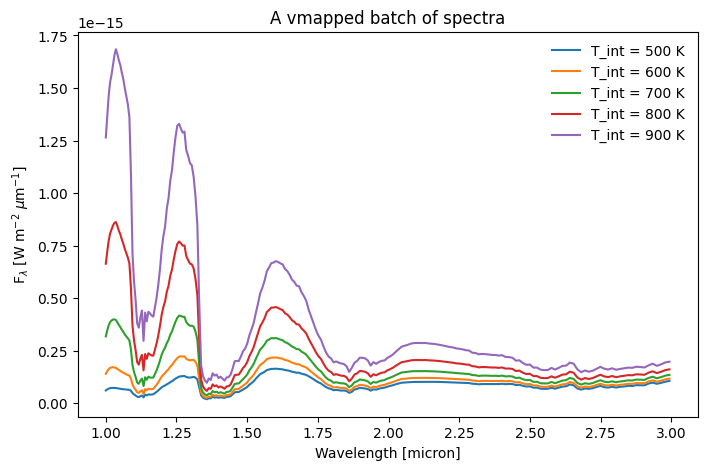

In [8]:
t_int_grid = jnp.linspace(500.0, 900.0, 5)

batched_spectra = vmap(
    lambda t_int: spectrum_from_dynamic_params({**base_dynamic_parameters, "T_int": t_int})
)(t_int_grid)

fig, ax = plt.subplots(figsize=(8, 5))
for t_int, spectrum in zip(np.asarray(t_int_grid), np.asarray(batched_spectra)):
    ax.plot(np.asarray(wavelengths), spectrum, label=f"T_int = {t_int:.0f} K")
ax.set_xlabel("Wavelength [micron]")
ax.set_ylabel(r"F$_{\lambda}$ [W m$^{-2}$ $\mu$m$^{-1}$]")
ax.set_title("A vmapped batch of spectra")
ax.legend(frameon=False)

## 7. Gradients as a Function of Wavelength

A very useful retrieval diagnostic is the spectral Jacobian

$$
J_{ij} = \frac{\partial F_{\lambda_i}}{\partial \theta_j},
$$

where $F_{\lambda_i}$ is the model flux at wavelength index $i$ and $\theta_j$ is one of the model parameters. This tells you which parts of the spectrum constrain which parameters.

The pattern below mirrors the approach used in JAX retrieval development notebooks: use `jax.jacfwd` to differentiate the per-wavelength scalar model output with respect to a parameter pytree, then use `jax.vmap` to repeat that calculation across all wavelengths. This is directly useful for local sensitivity analysis, Fisher-matrix calculations, and gradient-based samplers.

In [9]:
gradient_parameter_names = (
    "T_int",
    "log_g",
    "H2O__POKAZATEL",
    "CO-NatAbund",
)

base_gradient_parameters = {
    name: jnp.asarray(base_parameter_mapping[name])
    for name in gradient_parameter_names
}

def flux_at_wavelength(variable_parameters, wavelength_index):
    params = PhysicalParams.from_mapping({**base_parameter_mapping, **variable_parameters})
    model_result = guillot_emission(emission_context, params)
    return model_result.spectrum[wavelength_index]

per_wavelength_jacobian = jacfwd(flux_at_wavelength)
vmapped_gradients = vmap(
    lambda wavelength_index: per_wavelength_jacobian(base_gradient_parameters, wavelength_index)
)(jnp.arange(wavelengths.size))

gradients = {
    name: vmapped_gradients[name]
    for name in gradient_parameter_names
}

print({name: gradients[name].shape for name in gradient_parameter_names})

{'T_int': (220,), 'log_g': (220,), 'H2O__POKAZATEL': (220,), 'CO-NatAbund': (220,)}


Text(0, 0.5, 'F$_{\\lambda}$ [W m$^{-2}$ $\\mu$m$^{-1}$]')

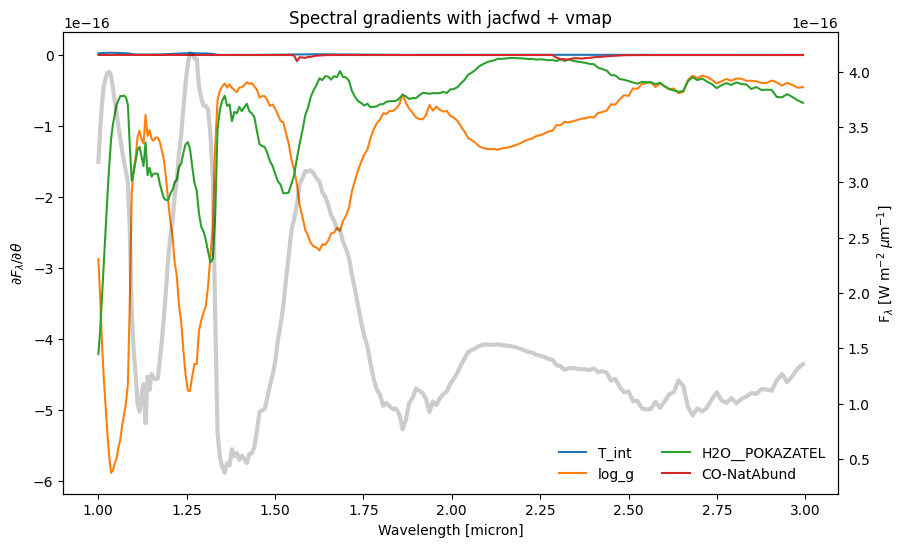

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))
for name in gradient_parameter_names:
    ax.plot(np.asarray(wavelengths), np.asarray(gradients[name]), label=name)

ax.set_xlabel("Wavelength [micron]")
ax.set_ylabel(r"$\partial F_{\lambda} / \partial \theta$")
ax.set_title("Spectral gradients with jacfwd + vmap")
ax.legend(frameon=False, ncol=2, loc="lower right")

flux_ax = ax.twinx()
flux_ax.plot(np.asarray(wavelengths), np.asarray(flux), color="k", linewidth=3, alpha=0.2)
flux_ax.set_ylabel(r"F$_{\lambda}$ [W m$^{-2}$ $\mu$m$^{-1}$]")

## 8. Choosing the Execution Device Explicitly

The same pRT model code can be executed on different devices by moving the inputs with `jax.device_put`. JAX will compile a backend-specific executable as needed. See the [JAX installation guide](https://docs.jax.dev/en/latest/installation.html) for backend-specific wheels and the [device-placement discussion](https://docs.jax.dev/en/latest/faq.html#controlling-data-and-computation-placement-on-devices) for more details.

In [11]:
default_device_spectrum = jit_spectrum_from_dynamic_params(base_dynamic_parameters)
default_device_spectrum.block_until_ready()
print("Default-device spectrum:", default_device_spectrum.devices())

cpu_device = next(device for device in jax.devices() if device.platform == "cpu")
cpu_dynamic_parameters = jax.device_put(base_dynamic_parameters, device=cpu_device)
cpu_spectrum = jit_spectrum_from_dynamic_params(cpu_dynamic_parameters)
cpu_spectrum.block_until_ready()
print("CPU spectrum:", cpu_spectrum.devices())

gpu_devices = [device for device in jax.devices() if device.platform == "gpu"]
if gpu_devices:
    gpu_dynamic_parameters = jax.device_put(base_dynamic_parameters, device=gpu_devices[0])
    gpu_spectrum = jit_spectrum_from_dynamic_params(gpu_dynamic_parameters)
    gpu_spectrum.block_until_ready()
    print("GPU spectrum:", gpu_spectrum.devices())
else:
    print("No GPU detected. Install a GPU-enabled JAX build to run the same code on accelerators.")

Default-device spectrum: {CpuDevice(id=0)}
CPU spectrum: {CpuDevice(id=0)}
No GPU detected. Install a GPU-enabled JAX build to run the same code on accelerators.


## Why This Matters for Atmospheric Retrievals

In atmospheric retrievals, these JAX features translate directly into practical gains:

- `jax.numpy` keeps model-building code close to familiar NumPy-style scientific Python.
- `jit` amortizes the cost of repeated forward-model evaluations across many likelihood calls.
- automatic differentiation exposes parameter sensitivities and Jacobians without hand-written derivatives.
- `vmap` batches spectra, Jacobians, or proposal points without slow Python loops.
- device placement lets the same retrieval code scale from a laptop CPU to a workstation GPU.

Further reading:

- [JAX quickstart](https://docs.jax.dev/en/latest/quickstart.html)
- [Thinking in JAX](https://docs.jax.dev/en/latest/notebooks/thinking_in_jax.html)
- [`jax.numpy` API](https://docs.jax.dev/en/latest/jax.numpy.html)
- [JIT compilation](https://docs.jax.dev/en/latest/jit-compilation.html)
- [Automatic differentiation](https://docs.jax.dev/en/latest/automatic-differentiation.html)
- [Automatic vectorization with `vmap`](https://docs.jax.dev/en/latest/automatic-vectorization.html)
- [JAX installation and devices](https://docs.jax.dev/en/latest/installation.html)
- ["Getting Started"](./getting_started.ipynb)
- ["Retrievals: Using the Model Functions"](./retrieval_model_functions_tutorial.ipynb)